<a href="https://colab.research.google.com/github/profedaniel86/Funtamentos_de_Anal-tica_II/blob/main/3.Series_NN_RNN_TCN/4.Sesi%C3%B3n%2010/Bases%20de%20datos%20y%20Notebooks%20sesi%C3%B3n%2010-20250713/02_06_PyTorch_MultivariableTimeSeries_LSTM_vs_TCN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pronóstico de series de tiempo multivariadas con PyTorch: de RNN/LSTM/GRU a TCN

Los objetivos de este notebook son:
- Ilustrar cómo manejar un `Dataset` de PyTorch que permita obtener batches de datos basados en una serie de tiempo multivariada, dada una ventana histórica predictiva y una ventana futura a predecir.
- Repasar el manejo de los módulos `nn.RNN`, `nn.LSTM` y `nn.GRU` de PyTorch para crear capas recurrentes.
- Construir **desde cero en PyTorch** (sin Darts ni otras librerías) una **Red Convolucional Temporal (TCN)**: convoluciones causales, dilatación, campo receptivo y bloques residuales.
- Resolver **el mismo problema** de pronóstico con ambos enfoques y **comparar** su desempeño predictivo y, sobre todo, su **costo computacional** (tiempo de entrenamiento, de inferencia y cómo escala con la longitud de la ventana histórica).

Este notebook está basado en material encontrado en:
- *Time series forecasting*, https://www.tensorflow.org/tutorials/structured_data/time_series
- *Deep Learning with Python*, François Chollet, Manning, 2021.
- *Machine Learning with PyTorch and Scikit-Learn*, Sebastian Raschka, Yuxi Liu & Vahid Mirjalili, Packt, 2022.
- *Dive into Deep Learning*, Aston Zhang, Zachary C. Lipton, Mu Li & Alexander J. Smola, https://d2l.ai/, 2022.
- *An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling*, Shaojie Bai, J. Zico Kolter & Vladlen Koltun, 2018, https://arxiv.org/abs/1803.01271
- *WaveNet: A Generative Model for Raw Audio*, Aäron van den Oord et al., 2016, https://arxiv.org/abs/1609.03499
- *PyTorch*, https://pytorch.org/

# 1. Establecimiento del ambiente de desarrollo y ejecución

Preparamos el ambiente de desarrollo y ejecución, cargando librerías, verificando el dispositivo disponible (CPU o CUDA), y definiendo una función para resetear las semillas aleatorias.

> **Recomendación:** en Colab, active una GPU (*Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*). Las comparaciones de tiempo de la sección 7 son mucho más ilustrativas en GPU, porque la principal ventaja computacional de la TCN es el **paralelismo**.

In [4]:
import os, random, math, time
from zipfile import ZipFile

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.parametrizations import weight_norm
from torch.utils.data import Dataset, DataLoader, BatchSampler, RandomSampler, SequentialSampler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
print("PyTorch", torch.__version__)

PyTorch 2.11.0+cu130


In [5]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda:0')
    print("Utilizamos la primera GPU disponible:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device('cpu')
    print("No hay GPU, toca correr todo en CPU")

DEVICE

Utilizamos la primera GPU disponible: Tesla T4


device(type='cuda', index=0)

In [6]:
def reset_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def sincronizar(device=DEVICE):
    """Las operaciones en GPU son asíncronas: para medir tiempos correctamente
    hay que esperar a que la GPU termine antes de leer el reloj."""
    if torch.device(device).type == 'cuda':
        torch.cuda.synchronize()

# 2. Serie de tiempo multivariada

Vamos a utilizar un <a href="https://www.bgc-jena.mpg.de/wetter/" class="external">dataset de clima</a>, con series de tiempo multivariadas, recopilado por el <a href="https://www.bgc-jena.mpg.de" class="external">Max Planck Institute for Biogeochemistry</a>.

El dataset contiene **14 variables** como la temperatura del aire, la presión atmosférica, la humedad, etc. Cada serie de tiempo tiene un valor registrado **cada 10 minutos**, empezando en 2003. Por eficiencia, vamos a descargar los datos de 2009 a 2016. Esta sección del dataset fue preparada por François Chollet para su libro [Deep Learning with Python](https://www.manning.com/books/deep-learning-with-python).

In [35]:
URL = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'
DATA_DIR = 'datos'
ZIP_PATH = os.path.join(DATA_DIR, 'jena_climate_2009_2016.csv.zip')
CSV_PATH = os.path.join(DATA_DIR, 'jena_climate_2009_2016.csv')

os.makedirs(DATA_DIR, exist_ok=True)
if os.path.exists(CSV_PATH):
    print("El archivo ya existe")
else:
    if not os.path.exists(ZIP_PATH):
        r = requests.get(URL, allow_redirects=True)
        r.raise_for_status()
        with open(ZIP_PATH, 'wb') as f:
            f.write(r.content)
    with ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(path=DATA_DIR)
    print("Archivo descargado y descomprimido en", DATA_DIR)

Archivo descargado y descomprimido en datos


In [36]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(420551, 15)


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


La primera columna contiene el *timestamp*, con cada observación registrada cada 10 minutos. Es decir, 24\*6=144 observaciones al día.

Si quisiéramos, por ejemplo, predecir la temperatura dentro de 12 horas a partir de los últimos 5 días, tendríamos una ventana histórica de 5\*144=720 pasos de tiempo, para predecir un valor 6\*12=72 pasos en el futuro.

El total de observaciones del dataset, de 2009 a 2016, es de más de 420000 registros. Establecemos un punto de corte para separar el dataset de entrenamiento y de validación en 300000 registros de training, que equivalen aproximadamente a 2100 días.

In [37]:
TRAIN_SPLIT = 300000

De las 14 variables que contiene el dataset, vamos a escoger 3 por simplicidad como variables predictivas: la presión atmosférica, la temperatura del aire y la densidad del aire. Establecemos además la variable del timestamp como índice.

In [38]:
variables_a_considerar = ['p (mbar)', 'T (degC)', 'rho (g/m**3)']
IDX_TARGET = 1   # la temperatura es la variable a pronosticar

features = df[variables_a_considerar]
features.index = df['Date Time']
features.head()

,p (mbar),T (degC),rho (g/m**3)
Date Time,,,
01.01.2009 00:10:00,996.52,-8.02,1307.75
01.01.2009 00:20:00,996.57,-8.41,1309.80
01.01.2009 00:30:00,996.53,-8.51,1310.24
01.01.2009 00:40:00,996.51,-8.31,1309.19
01.01.2009 00:50:00,996.51,-8.27,1309.00


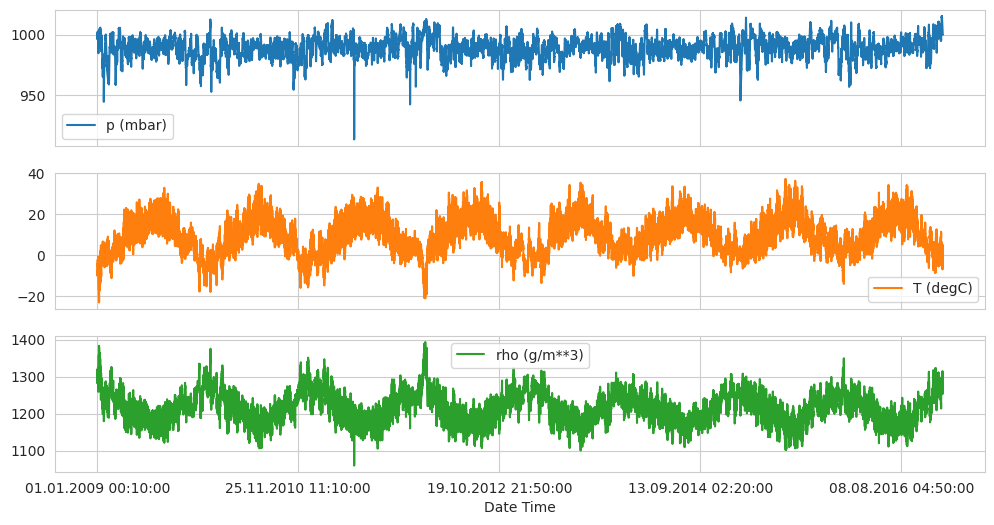

In [ ]:
_ = features.plot(subplots=True, figsize=(12, 6))

Los valores de las variables tienen diferentes escalas. Para facilitar el proceso y mejorar la estabilidad de los modelos, normalizamos cada serie de manera independiente, teniendo en cuenta que los parámetros de normalización **solo deben calcularse con el dataset de entrenamiento**.

In [39]:
dataset = features.values.astype(np.float32)
promedios = dataset[:TRAIN_SPLIT].mean(axis=0)
desviaciones = dataset[:TRAIN_SPLIT].std(axis=0)
dataset = (dataset - promedios) / desviaciones

num_features = dataset.shape[1]

def a_grados(z):
    """Convierte valores normalizados de temperatura a grados Celsius."""
    return z * desviaciones[IDX_TARGET] + promedios[IDX_TARGET]

# 3. Subclase de `Dataset` para pronóstico multivariado

Vamos a crear una subclase de `Dataset` para obtener las instancias de entrenamiento y validación de una tarea de *forecasting* sobre las series multivariadas. Esta clase recibe los siguientes parámetros:

- **dataset**: arreglo de rango 2, con el primer eje temporal y el segundo conteniendo las variables.
- **target**: arreglo de rango 1 con la variable que se desea predecir.
- **start_index**: índice desde el cuál se quieren considerar los valores de la serie.
- **end_index**: índice hasta dónde se quieren considerar los valores de la serie (`None` = hasta el final).
- **history_size**: tamaño de la ventana de valores históricos predictores. Si **step** es mayor a 1, no todos los datos del histórico se tendrán en cuenta.
- **target_size**: número de pasos en el futuro, después del fin de la ventana, que definen el valor a predecir. Si **single_step** es `True`, solo se considera el valor en la posición **target_size** contada desde el final de la ventana. Si **single_step** es `False`, se consideran todos los **target_size** valores siguientes a la ventana.
- **step**: salto entre los valores escogidos dentro de la ventana histórica. Si vale 1 se escogen todos; si vale 2 se escoge el primero, el tercero, el quinto, etc. Útil cuando la serie varía poco entre observaciones consecutivas.
- **single_step**: `False` por defecto. Indica si se pronostica un único valor futuro o una ventana de valores.
- **device**: dispositivo donde se guardan los datos (CPU o GPU).

**Sobre la implementación.** En lugar de recorrer la serie con un ciclo `for` y copiar cada ventana (lo que con 300000 ventanas de 720 pasos ocuparía varios GB), usamos `Tensor.unfold`, que crea una **vista** de todas las ventanas deslizantes **sin copiar memoria**. Cada ventana solo se materializa cuando se pide en un batch. Esto hace que crear el dataset sea instantáneo y nos permitirá, más adelante, experimentar con ventanas largas (por ejemplo, 720 pasos con `step=1`).

In [40]:
class SerieTiempoMultivariadaDataset(Dataset):
    def __init__(self, dataset, target, start_index, end_index,
                 history_size, target_size, step, single_step=False, device='cpu'):
        serie = torch.as_tensor(dataset, dtype=torch.float32, device=device)
        objetivo = torch.as_tensor(target, dtype=torch.float32, device=device)

        if end_index is None:
            end_index = len(dataset) - target_size
        primer_i = start_index + history_size     # primer instante a pronosticar
        self.n = end_index - primer_i             # número de instancias

        # unfold crea una VISTA con todas las ventanas deslizantes de tamaño history_size:
        # forma (T - history_size + 1, num_features, history_size)
        ventanas = serie.unfold(0, history_size, 1)[start_index:start_index + self.n]
        self.data = ventanas[:, :, ::step]        # submuestreo dentro de la ventana -> (N, features, L)

        if single_step:
            self.labels = objetivo[primer_i + target_size:end_index + target_size].unsqueeze(-1)  # (N, 1)
        else:
            self.labels = objetivo.unfold(0, target_size, 1)[primer_i:end_index]                # (N, target_size)

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        # idx puede ser un entero o una lista de índices (un batch completo)
        x = self.data[idx]                               # (features, L) o (B, features, L)
        return x.transpose(-1, -2).contiguous(), self.labels[idx]   # (L, features) o (B, L, features)

Para entender el funcionamiento de esta clase, analicemos un caso en el que:
- se quiera pronosticar la temperatura, **target**=dataset[:, 1]
- con un dataset base que solo considere los primeros 100 datos temporales (**start_index**=0, **end_index**=100)
- una ventana temporal de 1 hora (**history_size** de 6 pasos de 10 minutos)
- tomando solo los valores cada 20 minutos (un **step** de 2)
- para predecir el valor inmediatamente posterior, sin salto futuro (**target_size**=0 y **single_step**=True)

In [41]:
past_history = 6    # la última hora
future_target = 0   # el valor de los siguientes 10 minutos
STEP = 2            # valores cada 20 minutos

dataset_ejemplo = SerieTiempoMultivariadaDataset(dataset, dataset[:, IDX_TARGET], 0, 100,
                                                 past_history, future_target, STEP, single_step=True)
len(dataset_ejemplo)

94

In [16]:
dataset[:8].shape

(8, 3)

Como tenemos una ventana histórica de 6 valores, el dataset solo podrá tener 100-6=94 instancias.
Analicemos los primeros valores de las series para entender las instancias de datos y labels que retorna el `Dataset`:

In [ ]:
dataset[:8]

array([[ 0.955475  , -1.9976633 ,  2.235075  ],
       [ 0.96154475, -2.0428193 ,  2.2852373 ],
       [ 0.95669043, -2.0543976 ,  2.2960021 ],
       [ 0.9542595 , -2.0312407 ,  2.2703087 ],
       [ 0.9542595 , -2.0266094 ,  2.265661  ],
       [ 0.9530441 , -2.0011368 ,  2.2377663 ],
       [ 0.9530441 , -1.9513493 ,  2.184426  ],
       [ 0.9530441 , -1.9513493 ,  2.184668  ]], dtype=float32)

In [ ]:
dataset_ejemplo[0]

(tensor([[ 0.9555, -1.9977,  2.2351],
         [ 0.9567, -2.0544,  2.2960],
         [ 0.9543, -2.0266,  2.2657]]),
 tensor([-1.9513]))

La instancia 0 toma las filas 0, 2 y 4 (una cada 20 minutos dentro de la primera hora) y su label es la temperatura de la fila 6.

Verifiquemos que la versión con `unfold` produce exactamente lo mismo que la versión con un ciclo `for` (la implementación "ingenua"):

In [42]:
def ventanas_con_ciclo(dataset, target, start_index, end_index, history_size, target_size, step):
    data, labels = [], []
    for i in range(start_index + history_size, end_index):
        data.append(dataset[range(i - history_size, i, step)])
        labels.append([target[i + target_size]])
    return np.array(data), np.array(labels)

d_ciclo, l_ciclo = ventanas_con_ciclo(dataset, dataset[:, IDX_TARGET], 0, 2000, 120, 12, 6)
ds_unfold = SerieTiempoMultivariadaDataset(dataset, dataset[:, IDX_TARGET], 0, 2000, 120, 12, 6, single_step=True)
x_unfold, y_unfold = ds_unfold[list(range(len(ds_unfold)))]
print("¿Mismas ventanas?", np.allclose(d_ciclo, x_unfold.numpy()), "| ¿Mismos labels?", np.allclose(l_ciclo, y_unfold.numpy()))

¿Mismas ventanas? True | ¿Mismos labels? True


Ahora sí establezcamos los datasets de training y validación. Vamos a considerar:
- pronosticar la temperatura, **target**=dataset[:, 1]
- un dataset de training con los primeros 300000 datos temporales (**start_index**=0, **end_index**=TRAIN_SPLIT)
- una ventana predictiva de 5 días (**history_size** de 6\*24\*5=720 pasos de 10 minutos)
- tomando solo valores cada hora (un **step** de 6)
- para predecir el valor dentro de 12 horas (**target_size** de 6\*12=72, y **single_step**=True)

Los datos se guardan directamente en el dispositivo de procesamiento (`DEVICE`), de modo que en GPU la construcción de los batches no requiere transferencias CPU→GPU.

In [43]:
PAST_HISTORY = 720   # los 5 días anteriores
FUTURE_TARGET = 72   # valor dentro de 12 horas
STEP = 6             # valores cada hora

train_data = SerieTiempoMultivariadaDataset(dataset, dataset[:, IDX_TARGET], 0, TRAIN_SPLIT,
                                            PAST_HISTORY, FUTURE_TARGET, STEP, single_step=True, device=DEVICE)
val_data = SerieTiempoMultivariadaDataset(dataset, dataset[:, IDX_TARGET], TRAIN_SPLIT, None,
                                          PAST_HISTORY, FUTURE_TARGET, STEP, single_step=True, device=DEVICE)
print("Instancias de training:", len(train_data), "| de validación:", len(val_data))

Instancias de training: 299280 | de validación: 119759


Cada instancia es una dupla con los datos predictivos y el label a predecir. Como tenemos 720 pasos históricos pero tomamos uno de cada 6, la ventana histórica queda de 720/6=120 valores, con un único valor de *ground truth* a predecir.

In [44]:
VENTANA_HISTORICA = PAST_HISTORY // STEP
print(train_data[0][0].shape, train_data[0][1].shape)

torch.Size([120, 3]) torch.Size([1])


Creamos los `DataLoader` de entrenamiento (barajado con `shuffle`, para no introducir sesgos de orden) y de validación (sin barajar).

Como nuestro `Dataset` puede entregar un batch completo con una sola operación de indexación, usamos un `BatchSampler`: el `DataLoader` le pide al dataset **una lista de 256 índices a la vez**, en lugar de 256 llamadas individuales a `__getitem__` seguidas de un `torch.stack`. Así evitamos que la carga de datos domine los tiempos que queremos comparar entre modelos.

In [45]:
BATCH_SIZE = 256

def crear_dataloader(ds, batch_size=BATCH_SIZE, shuffle=False):
    sampler = RandomSampler(ds) if shuffle else SequentialSampler(ds)
    return DataLoader(ds, sampler=BatchSampler(sampler, batch_size=batch_size, drop_last=False),
                      batch_size=None)

train_dataloader = crear_dataloader(train_data, shuffle=True)
val_dataloader = crear_dataloader(val_data, shuffle=False)

train_features, train_labels = next(iter(train_dataloader))
print(train_features.shape, train_labels.shape, train_features.device)

torch.Size([256, 120, 3]) torch.Size([256, 1]) cuda:0


Comparemos el tiempo de recorrer 200 batches con el `DataLoader` clásico (instancia por instancia) y con el `BatchSampler`:

In [46]:
def tiempo_recorrido(loader, n_batches=200):
    sincronizar()
    t0 = time.perf_counter()
    for i, (xb, yb) in enumerate(loader):
        if i + 1 == n_batches:
            break
    sincronizar()
    return time.perf_counter() - t0

loader_clasico = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
print(f"DataLoader clásico:    {tiempo_recorrido(loader_clasico):.2f} s")
print(f"DataLoader por batches: {tiempo_recorrido(train_dataloader):.2f} s")

DataLoader clásico:    1.19 s
DataLoader por batches: 0.08 s


# 4. Funciones de entrenamiento, evaluación y medición de tiempos

Definimos varias funciones que usaremos con **todos** los modelos, de modo que la comparación sea justa (mismos datos, mismo optimizador, mismo número de épocas, mismo tamaño de batch):
- `entrenar_modelo`: ciclo de épocas de entrenamiento. Además de los losses, registra el **tiempo de entrenamiento de cada época** (sin incluir la validación).
- `pronostico`: inferencia sobre un dataset completo.
- `plot_losses` y `plot_reals_vs_preds`: gráficos de diagnóstico.
- `experimento`: crea el modelo, lo entrena, mide tiempos y calcula métricas en grados Celsius.

In [47]:
def entrenar_modelo(modelo, train_dataset, val_dataset, batch_size=BATCH_SIZE,
                    learning_rate=1e-3, epocas=5, verbose=False):
    """Ciclo de épocas de entrenamiento de un modelo de forecasting.

    :returns: el modelo entrenado y un diccionario con los losses de training y
              validación, y el tiempo de entrenamiento (en segundos) de cada época.
    """
    train_loader = crear_dataloader(train_dataset, batch_size, shuffle=True)
    val_loader = crear_dataloader(val_dataset, batch_size, shuffle=False)

    modelo = modelo.to(DEVICE)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(modelo.parameters(), lr=learning_rate)

    historial = {'train_loss': [], 'val_loss': [], 'tiempo_epoca': []}

    for epoca in range(epocas):
        # ---- entrenamiento (cronometrado) ----
        modelo.train()
        train_loss = 0.0
        sincronizar()
        t0 = time.perf_counter()
        for batch_features, batch_labels in train_loader:
           # Nos aseguramos que los inputs del modelo estén en el mismo dispositivo
            batch_features = batch_features.to(DEVICE)
            batch_labels = batch_labels.to(DEVICE)
            # Generar las predicciones
            batch_preds = modelo(batch_features)
            # Comparar con las realidades a partir del loss function
            loss = loss_fn(batch_preds, batch_labels)
            # Calcular los gradientes de la función de pérdida
            loss.backward()
            # Actualizar parámetros con los gradientes
            optimizer.step()
            # Resetear los gradientes para no reacumularlos
            optimizer.zero_grad()

            train_loss += loss.detach() * batch_labels.size(0)   # acumulamos en el device, sin .item() por batch
        sincronizar()
        tiempo = time.perf_counter() - t0

        # ---- validación ----
        modelo.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch_features, batch_labels in val_loader:
                batch_features = batch_features.to(DEVICE)
                batch_labels = batch_labels.to(DEVICE)
                val_loss += loss_fn(modelo(batch_features), batch_labels) * batch_labels.size(0)

        historial['train_loss'].append(train_loss.item() / len(train_dataset))
        historial['val_loss'].append(val_loss.item() / len(val_dataset))
        historial['tiempo_epoca'].append(tiempo)

        if verbose:
            print(f"época {epoca}: loss {historial['train_loss'][-1]:.5f}, "
                  f"val loss {historial['val_loss'][-1]:.5f} -- tiempo de entrenamiento: {tiempo:.2f} s")
    return modelo, historial

In [48]:
def pronostico(modelo, forecast_dataset, batch_size=BATCH_SIZE):
    modelo.eval()
    preds = []
    with torch.no_grad():
        for batch_features, _ in crear_dataloader(forecast_dataset, batch_size, shuffle=False):
            preds.append(modelo(batch_features.to(DEVICE)).squeeze(-1))
    return torch.cat(preds).cpu().numpy()


def plot_losses(historial, titulo='model loss'):
    plt.figure(figsize=(6, 3), dpi=120)
    plt.plot(historial['train_loss'], label='train')
    plt.plot(historial['val_loss'], label='val')
    plt.legend(loc='upper right')
    plt.title(titulo)
    plt.ylabel('loss (MSE)')
    plt.xlabel('epoch')
    plt.show()


def plot_reals_vs_preds(reals, preds, n_puntos=144 * 14, titulo="Valores reales vs. predichos"):
    """Grafica (en °C) los primeros n_puntos del conjunto de validación (por defecto, 14 días)."""
    plt.figure(figsize=(12, 4))
    plt.plot(reals[:n_puntos], label='real', lw=1)
    plt.plot(preds[:n_puntos], label='pronóstico', lw=1)
    plt.title(titulo)
    plt.xlabel("instancia de validación (pasos de 10 minutos)")
    plt.ylabel("T (°C)")
    plt.legend(loc='upper left')
    plt.show()


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

In [49]:
EPOCAS = 5
LEARNING_RATE = 1e-3

def experimento(nombre, crear_modelo, train_data=train_data, val_data=val_data,
                epocas=EPOCAS, mostrar_graficos=False, verbose=True):
    """Crea un modelo con la función crear_modelo(), lo entrena, mide tiempos y calcula métricas."""
    reset_seed()
    modelo = crear_modelo()
    modelo, historial = entrenar_modelo(modelo, train_data, val_data, BATCH_SIZE,
                                        LEARNING_RATE, epocas, verbose=verbose)

    sincronizar()
    t0 = time.perf_counter()
    preds = pronostico(modelo, val_data)
    sincronizar()
    tiempo_inferencia = time.perf_counter() - t0

    reals_c = a_grados(val_data.labels.squeeze(-1).cpu().numpy())
    preds_c = a_grados(preds)

    resultado = {
        'modelo': nombre,
        'parámetros': contar_parametros(modelo),
        'val loss (MSE)': historial['val_loss'][-1],
        'MAE (°C)': mean_absolute_error(reals_c, preds_c),
        'RMSE (°C)': math.sqrt(mean_squared_error(reals_c, preds_c)),
        # se descarta la primera época: incluye "calentamiento" (inicialización de cuDNN, caches, etc.)
        's/época (entren.)': float(np.mean(historial['tiempo_epoca'][1:] or historial['tiempo_epoca'])),
        's inferencia (val)': tiempo_inferencia,
    }
    print(f"==> {nombre}: MAE {resultado['MAE (°C)']:.3f} °C | "
          f"{resultado['s/época (entren.)']:.2f} s/época | {resultado['parámetros']} parámetros")

    if mostrar_graficos:
        plot_losses(historial, f"{nombre}: loss")
        plot_reals_vs_preds(reals_c, preds_c, titulo=f"{nombre}: valores reales vs. predichos")
    return modelo, historial, resultado

# 5. Modelos recurrentes: `RNN`, `LSTM` y `GRU`

Un submódulo `nn.LSTM` permite crear una o varias capas recurrentes de tipo **LSTM**, para lo cual se debe especificar:
- `input_size`: el número de variables de entrada de la capa inicial. **No confundir con el tamaño de la secuencia**: hablamos aquí de los **features**, por ejemplo, la temperatura, la presión atmosférica, la cantidad de precipitación.
- `hidden_size`: el número de neuronas recurrentes de cada capa apilada.
- `num_layers`: el número de capas recurrentes a apilar. Si hay más de una capa, las subsiguientes reciben como entrada los outputs de las anteriores.
- `batch_first`: si es `True`, los tensores de entrada y de salida presentan los ejes en el orden **(batch_size, timesteps, input_features)** en vez de **(timesteps, batch_size, input_features)**. Esto no aplica para los estados intermedios, solo para entradas y salidas. Por defecto es `False`.
- `dropout`: si es diferente de 0, probabilidad utilizada por capas de `Dropout` intermedias entre las capas recurrentes.
- `bidirectional`: controla si las capas recurrentes son bidireccionales o no. Por defecto es `False`.

Los módulos `nn.RNN` y `nn.GRU` reciben los mismos parámetros.

El llamado a un módulo `LSTM` retorna:
- un tensor de **outputs** con los estados de salida de la última capa recurrente para **todos** los pasos de tiempo, con ejes **(batch_size, timesteps, hidden_size)** si `batch_first=True`.
- una tupla con los **hidden states** $h_n$ y los **cell states** $c_n$ del último paso, para cada capa, con ejes **(num_layers (\*2 si bidireccional), batch_size, hidden_size)**.

Si no se envían estados iniciales $h_0$ y $c_0$, el módulo usa tensores de ceros por defecto.

In [9]:
reset_seed()
lstm = nn.LSTM(input_size=5, hidden_size=3, num_layers=1, batch_first=True)
_ = [print(nombre, ":", p.shape) for nombre, p in lstm.named_parameters()]

weight_ih_l0 : torch.Size([12, 5])
weight_hh_l0 : torch.Size([12, 3])
bias_ih_l0 : torch.Size([12])
bias_hh_l0 : torch.Size([12])


Como tenemos una única capa LSTM con 3 neuronas (celdas), los parámetros a entrenar son:
- una matriz de 12x5, para conectar cada una de las 4 compuertas de las 3 celdas (4x3=12) con cada uno de los 5 features de entrada.
- una matriz de 12x3, para conectar cada una de las 4 compuertas de las 3 celdas con cada uno de los 3 estados del paso anterior.
- un vector de 12 sesgos para las conexiones con las entradas.
- un vector de 12 sesgos para las conexiones con los estados previos.

Procesemos una instancia con una secuencia de 3 pasos de tiempo y 5 features, organizada como (batch=1, timesteps=3, input_features=5):

In [10]:
x_seq = torch.tensor([[1.0] * 5, [2.0] * 5, [3.0] * 5]).reshape(1, 3, 5)
output, (hn, cn) = lstm(x_seq)
print("output:", output.shape, "\n", output)
print("hn:", hn.shape, "\n", hn)
print("cn:", cn.shape, "\n", cn)

output: torch.Size([1, 3, 3]) 
 tensor([[[-0.0170,  0.0160,  0.2735],
         [ 0.0645,  0.0477,  0.4026],
         [ 0.2172,  0.0411,  0.4880]]], grad_fn=<TransposeBackward0>)
hn: torch.Size([1, 1, 3]) 
 tensor([[[0.2172, 0.0411, 0.4880]]], grad_fn=<StackBackward0>)
cn: torch.Size([1, 1, 3]) 
 tensor([[[0.6542, 0.5372, 1.0005]]], grad_fn=<StackBackward0>)


Observe que `hn` coincide con el último paso de `output`. Un detalle clave para la comparación con la TCN: **para calcular el estado del paso $t$ se necesita el estado del paso $t-1$**. El procesamiento de la secuencia es inherentemente **secuencial**: no se puede paralelizar a lo largo del eje del tiempo.

El módulo `nn.GRU` funciona igual, salvo que solo produce un tensor de estados escondidos (no tiene *cell state*) y tiene 3 compuertas en lugar de 4:

In [28]:
reset_seed()
gru = nn.GRU(input_size=5, hidden_size=3, num_layers=1, batch_first=True)
_ = [print(nombre, ":", p.shape) for nombre, p in gru.named_parameters()]
output, hn = gru(x_seq)
print("output:", output.shape, "| hn:", hn.shape)

weight_ih_l0 : torch.Size([9, 5])
weight_hh_l0 : torch.Size([9, 3])
bias_ih_l0 : torch.Size([9])
bias_hh_l0 : torch.Size([9])
output: torch.Size([1, 3, 3]) | hn: torch.Size([1, 1, 3])


## 5.1 Modelo de forecasting recurrente

Creamos una sola clase que, según el parámetro `tipo`, use un submódulo `nn.RNN`, `nn.LSTM` o `nn.GRU`, seguido de una capa densa `nn.Linear` de salida (sin función de activación). Hiperparámetros:
- `input_dim`: número de *features* predictivos.
- `hidden_dim`: número de neuronas escondidas en cada capa recurrente.
- `layer_dim`: número de capas recurrentes.
- `output_dim`: número de neuronas de salida de la capa densa final.

La capa `nn.Linear` final recibe **solo los estados escondidos del último paso de tiempo**.

In [56]:
class ModeloRecurrente(nn.Module):
    def __init__(self, tipo, input_dim, hidden_dim, layer_dim, output_dim):
        super().__init__()
        self.tipo = tipo
        self.hidden_dim = hidden_dim
        self.layer_dim = layer_dim

        modulos = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}
        kwargs = {'nonlinearity': 'relu'} if tipo == 'rnn' else {}
        self.rnn = modulos[tipo](input_dim, hidden_dim, layer_dim, batch_first=True, **kwargs)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        # Estados iniciales en cero, con forma (layer_dim, batch_size, hidden_dim)
        h0 = torch.zeros(self.layer_dim, x.size(0), self.hidden_dim, device=x.device)
        if self.tipo == 'lstm':
            out, _ = self.rnn(x, (h0, torch.zeros_like(h0)))
        else:
            out, _ = self.rnn(x, h0)
        # "out" tiene ejes (batch_size, timesteps, hidden_dim); la capa densa solo recibe el último paso
        return self.fc(out[:, -1, :])

In [57]:
num_outputs = 1
modelo_prueba = ModeloRecurrente('lstm', num_features, hidden_dim=30, layer_dim=1, output_dim=num_outputs).to(DEVICE)
salida = modelo_prueba(train_features)
print("entrada:", train_features.shape, "-> salida:", salida.shape)

entrada: torch.Size([256, 120, 3]) -> salida: torch.Size([256, 1])


## 5.2 Entrenamiento de los modelos recurrentes

Entrenamos los tres modelos recurrentes con una capa de 30 neuronas escondidas (la mejor configuración encontrada en los barridos del notebook anterior; ver el Apéndice para repetir los barridos).


--- RNN ---
época 0: loss 0.17828, val loss 0.11936 -- tiempo de entrenamiento: 3.25 s
época 1: loss 0.10793, val loss 0.11237 -- tiempo de entrenamiento: 2.76 s
época 2: loss 0.10458, val loss 0.11004 -- tiempo de entrenamiento: 3.36 s
época 3: loss 0.10325, val loss 0.11316 -- tiempo de entrenamiento: 2.76 s
época 4: loss 0.10237, val loss 0.10974 -- tiempo de entrenamiento: 2.84 s
==> RNN: MAE 2.231 °C | 2.93 s/época | 1081 parámetros

--- LSTM ---
época 0: loss 0.15647, val loss 0.11003 -- tiempo de entrenamiento: 3.11 s
época 1: loss 0.10321, val loss 0.10377 -- tiempo de entrenamiento: 3.81 s
época 2: loss 0.09905, val loss 0.10321 -- tiempo de entrenamiento: 3.14 s
época 3: loss 0.09541, val loss 0.10132 -- tiempo de entrenamiento: 3.07 s
época 4: loss 0.09250, val loss 0.10430 -- tiempo de entrenamiento: 3.78 s
==> LSTM: MAE 2.203 °C | 3.45 s/época | 4231 parámetros

--- GRU ---
época 0: loss 0.15331, val loss 0.10882 -- tiempo de entrenamiento: 3.00 s
época 1: loss 0.10130, v

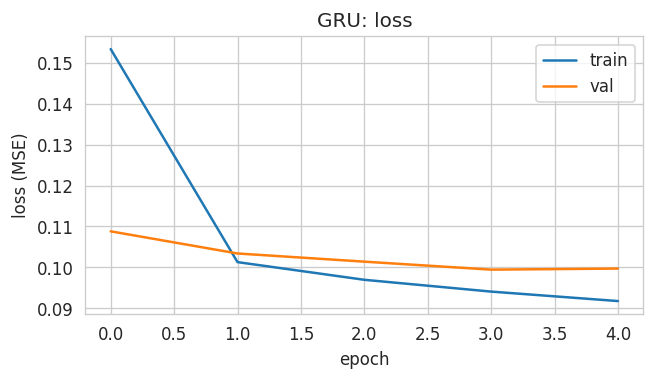

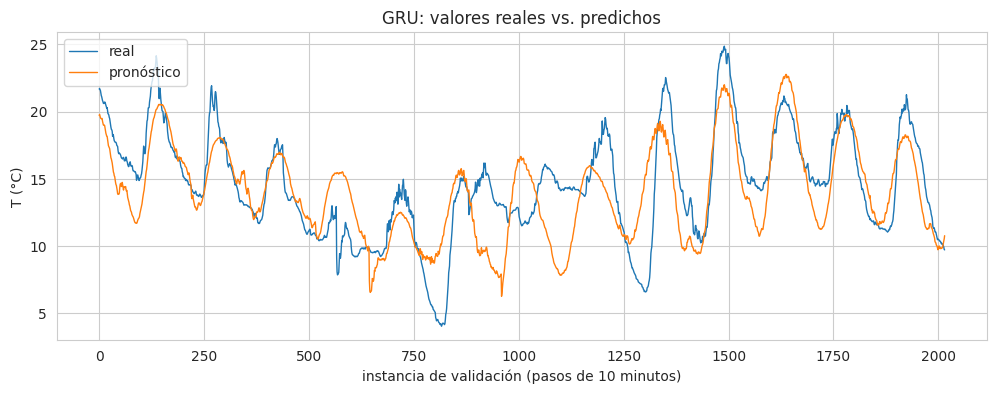

In [31]:
HIDDEN = 30
resultados = []
modelos = {}

for tipo in ['rnn', 'lstm', 'gru']:
    print(f"\n--- {tipo.upper()} ---")
    modelo, historial, resultado = experimento(
        tipo.upper(),
        lambda: ModeloRecurrente(tipo, num_features, HIDDEN, 1, num_outputs),
        mostrar_graficos=(tipo == 'gru'))
    modelos[tipo.upper()] = modelo
    resultados.append(resultado)

# 6. Redes Convolucionales Temporales (TCN)

Una **TCN** (*Temporal Convolutional Network*, Bai, Kolter & Koltun, 2018) reemplaza la recurrencia por una pila de **convoluciones 1D** a lo largo del eje del tiempo. Se basa en tres ideas:

1. **Convoluciones causales**: la salida en el instante $t$ solo depende de entradas en $t, t-1, t-2, \dots$ Nunca "mira al futuro".
2. **Convoluciones dilatadas**: el filtro salta $d$ pasos entre sus elementos. Duplicando $d$ en cada nivel ($1, 2, 4, 8, \dots$), el **campo receptivo** crece **exponencialmente** con la profundidad.
3. **Conexiones residuales**: cada bloque suma su entrada a su salida, lo que estabiliza el entrenamiento de redes profundas.

La diferencia computacional clave: en una RNN el paso $t$ espera al paso $t-1$; en una TCN **todas las posiciones de la secuencia se calculan a la vez**, con el mismo filtro, como en una CNN de imágenes. Esto es exactamente lo que una GPU hace bien.

## 6.1 `nn.Conv1d` sobre series de tiempo

`nn.Conv1d` espera tensores con ejes **(batch_size, canales, timesteps)**: los *features* juegan el papel de los canales (como los canales RGB de una imagen) y la convolución se desliza sobre el tiempo. Nuestro `DataLoader` entrega **(batch_size, timesteps, features)** (el formato `batch_first` de las RNN), así que basta transponer los dos últimos ejes.

In [11]:
reset_seed()
conv = nn.Conv1d(in_channels=5, out_channels=4, kernel_size=2)
_ = [print(nombre, ":", p.shape) for nombre, p in conv.named_parameters()]

x_conv = x_seq.transpose(1, 2)        # (1, 3, 5) -> (1, 5, 3)
print("entrada:", x_conv.shape, "-> salida:", conv(x_conv).shape)

weight : torch.Size([4, 5, 2])
bias : torch.Size([4])
entrada: torch.Size([1, 5, 3]) -> salida: torch.Size([1, 4, 2])


El filtro tiene forma (4 filtros de salida, 5 canales de entrada, 2 pasos de tiempo). Sin *padding*, una secuencia de 3 pasos con kernel 2 produce solo 2 salidas.

## 6.2 Convolución causal

Para que la salida tenga la misma longitud que la entrada **y** sea causal, agregamos $(k-1)\cdot d$ ceros **solo a la izquierda** de la secuencia ($k$: tamaño del kernel, $d$: dilatación). Así, la salida en $t$ combina $x_t, x_{t-d}, \dots, x_{t-(k-1)d}$.

Usamos además `weight_norm` (normalización de pesos), como en el artículo original de TCN.

In [12]:
class ConvolucionCausal(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation=1, usar_weight_norm=True):
        super().__init__()
        self.padding_izq = (kernel_size - 1) * dilation
        conv = nn.Conv1d(in_channels, out_channels, kernel_size, dilation=dilation)
        self.conv = weight_norm(conv) if usar_weight_norm else conv

    def forward(self, x):                        # x: (batch, canales, timesteps)
        x = F.pad(x, (self.padding_izq, 0))      # ceros solo a la izquierda (pasado)
        return self.conv(x)

**Verifiquemos la causalidad.** Perturbamos la entrada en $t=7$ y vemos qué salidas cambian. Con una convolución causal, solo deben cambiar las salidas en $t \geq 7$. Con una convolución estándar con `padding='same'` (centrada), también cambia la salida en $t=6$: **el modelo estaría usando información del futuro**, lo que en *forecasting* es una fuga de información.

In [33]:
reset_seed()
causal = ConvolucionCausal(1, 1, kernel_size=3, usar_weight_norm=False)
centrada = nn.Conv1d(1, 1, kernel_size=3, padding='same')

x = torch.arange(1., 11.).reshape(1, 1, 10)
x_perturbada = x.clone()
x_perturbada[..., 7] = 100.

with torch.no_grad():
    cambio_causal = (causal(x_perturbada) - causal(x)).abs().squeeze() > 0
    cambio_centrada = (centrada(x_perturbada) - centrada(x)).abs().squeeze() > 0

print("t:                     ", list(range(10)))
print("cambia (causal):       ", cambio_causal.int().tolist())
print("cambia (centrada/same):", cambio_centrada.int().tolist())

t:                      [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
cambia (causal):        [0, 0, 0, 0, 0, 0, 0, 1, 1, 1]
cambia (centrada/same): [0, 0, 0, 0, 0, 0, 1, 1, 1, 0]


## 6.3 Dilatación y campo receptivo

El **campo receptivo** es el número de pasos del pasado que pueden influir en una salida. Con una pila de convoluciones causales de kernel $k$ y dilataciones $d_1, d_2, \dots$, el campo receptivo es $R = 1 + (k-1)\sum_i d_i$.

La figura muestra una pila con $k=2$ y dilataciones $1, 2, 4, 8$: con solo 4 capas, la última salida "ve" $1 + 1\cdot(1+2+4+8) = 16$ pasos. Sin dilatación, harían falta 15 capas.

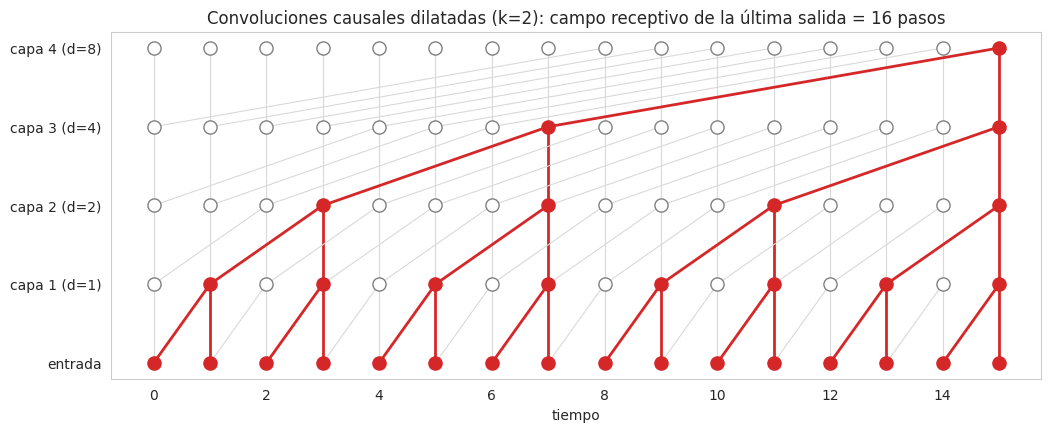

In [50]:
def dibujar_tcn_dilatada(dilataciones=(1, 2, 4, 8), k=2, L=16):
    n = len(dilataciones)
    fig, ax = plt.subplots(figsize=(12, 4.5))
    activos = {(n, L - 1)}                       # nodos que influyen en la última salida
    for nivel in range(n, 0, -1):
        d = dilataciones[nivel - 1]
        activos |= {(nivel - 1, t - j * d) for (lv, t) in list(activos) if lv == nivel
                    for j in range(k) if t - j * d >= 0}
    for nivel in range(1, n + 1):
        d = dilataciones[nivel - 1]
        for t in range(L):
            for j in range(k):
                s = t - j * d
                if s >= 0:
                    act = (nivel, t) in activos and (nivel - 1, s) in activos
                    ax.plot([s, t], [nivel - 1, nivel], color='tab:red' if act else '0.85',
                            lw=2 if act else 0.8, zorder=1)
    for nivel in range(n + 1):
        for t in range(L):
            act = (nivel, t) in activos
            ax.scatter(t, nivel, s=90, zorder=2, color='tab:red' if act else 'white',
                       edgecolor='tab:red' if act else '0.5')
    etiquetas = ['entrada'] + [f'capa {i + 1} (d={d})' for i, d in enumerate(dilataciones)]
    ax.set_yticks(range(n + 1), etiquetas)
    ax.set_xlabel('tiempo')
    ax.set_title(f'Convoluciones causales dilatadas (k={k}): campo receptivo de la última salida = '
                 f'{1 + (k - 1) * sum(dilataciones)} pasos')
    ax.grid(False)
    plt.show()

dibujar_tcn_dilatada()

En la TCN de Bai et al., cada **bloque residual** contiene **dos** convoluciones causales con la misma dilatación, y la dilatación se duplica de un bloque al siguiente ($d = 2^i$ en el bloque $i$). Con $n$ bloques y kernel $k$:

$$R = 1 + 2(k-1)\sum_{i=0}^{n-1} 2^i = 1 + 2(k-1)(2^n - 1)$$

Así podemos **elegir la arquitectura para cubrir exactamente la ventana histórica**: el número de bloques necesario para que $R \geq L$ es $n = \left\lceil \log_2\left(\frac{L-1}{2(k-1)} + 1\right) \right\rceil$. Note que crece **logarítmicamente** con $L$.

In [51]:
def campo_receptivo(kernel_size, num_bloques):
    return 1 + 2 * (kernel_size - 1) * (2 ** num_bloques - 1)

def bloques_necesarios(longitud, kernel_size):
    return max(1, math.ceil(math.log2((longitud - 1) / (2 * (kernel_size - 1)) + 1)))

tabla = []
for L in [24, 120, 240, 720, 4320]:
    for k in [2, 3, 5]:
        n = bloques_necesarios(L, k)
        tabla.append({'ventana L': L, 'kernel k': k, 'bloques': n, 'campo receptivo R': campo_receptivo(k, n)})
pd.DataFrame(tabla).pivot(index='ventana L', columns='kernel k', values='bloques')

kernel k,2,3,5
ventana L,,,
24,4,3,2
120,6,5,4
240,7,6,5
720,9,8,7
4320,12,11,10


La tabla muestra el número de bloques necesarios: para cubrir 4320 pasos (30 días cada 10 minutos) con $k=3$ bastan 11 bloques. Una RNN tendría que dar 4320 pasos secuenciales.

## 6.4 Bloque residual

Cada bloque residual de la TCN tiene la siguiente estructura:

```
x ──► ConvCausal(d) ─► ReLU ─► Dropout ─► ConvCausal(d) ─► ReLU ─► Dropout ──► (+) ─► ReLU ─► salida
│                                                                              ▲
└──────────────────── conexión residual (Conv1d 1x1 si cambian los canales) ───┘
```

La convolución $1\times1$ en la conexión residual solo se necesita cuando el número de canales de entrada y de salida difiere (por ejemplo, en el primer bloque: 3 *features* → 16 canales).

In [52]:
class BloqueResidualTCN(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout=0.1):
        super().__init__()
        self.conv1 = ConvolucionCausal(in_channels, out_channels, kernel_size, dilation)
        self.conv2 = ConvolucionCausal(out_channels, out_channels, kernel_size, dilation)
        self.dropout = nn.Dropout(dropout)
        self.residual = (nn.Conv1d(in_channels, out_channels, kernel_size=1)
                         if in_channels != out_channels else nn.Identity())

    def forward(self, x):                        # x: (batch, canales, timesteps)
        y = self.dropout(F.relu(self.conv1(x)))
        y = self.dropout(F.relu(self.conv2(y)))
        return F.relu(y + self.residual(x))

## 6.5 Modelo TCN de forecasting

El modelo completo apila `num_bloques` bloques residuales con dilataciones $1, 2, 4, \dots, 2^{n-1}$ y, **igual que en los modelos recurrentes**, pasa a una capa `nn.Linear` solo la representación del **último paso de tiempo** (que, gracias a la causalidad y al campo receptivo, resume toda la ventana histórica). Hiperparámetros:
- `input_dim`: número de *features* de entrada.
- `canales`: número de filtros (canales) en cada bloque, el equivalente a `hidden_dim`.
- `num_bloques`: número de bloques residuales. Si es `None`, se calcula para que el campo receptivo cubra `longitud_ventana`.
- `kernel_size`: tamaño del filtro temporal.
- `output_dim`: número de salidas.
- `dropout`: probabilidad de dropout dentro de los bloques.

In [58]:
class TCNModel(nn.Module):
    def __init__(self, input_dim, canales, output_dim, kernel_size=3, num_bloques=None,
                 longitud_ventana=None, dropout=0.1):
        super().__init__()
        if num_bloques is None:
            num_bloques = bloques_necesarios(longitud_ventana, kernel_size)
        self.campo_receptivo = campo_receptivo(kernel_size, num_bloques)

        bloques = [BloqueResidualTCN(input_dim if i == 0 else canales, canales,
                                     kernel_size, dilation=2 ** i, dropout=dropout)
                   for i in range(num_bloques)]
        self.tcn = nn.Sequential(*bloques)
        self.fc = nn.Linear(canales, output_dim)

    def forward(self, x):
        # x llega como (batch, timesteps, features); Conv1d espera (batch, features, timesteps)
        y = self.tcn(x.transpose(1, 2))          # (batch, canales, timesteps)
        return self.fc(y[:, :, -1])              # solo el último paso de tiempo

In [59]:
CANALES_TCN = 16
KERNEL_TCN = 3

modelo_tcn = TCNModel(num_features, CANALES_TCN, num_outputs, kernel_size=KERNEL_TCN,
                      longitud_ventana=VENTANA_HISTORICA).to(DEVICE)
print(modelo_tcn)
print(f"\nVentana histórica: {VENTANA_HISTORICA} pasos | bloques: {len(modelo_tcn.tcn)} | "
      f"campo receptivo: {modelo_tcn.campo_receptivo} pasos | parámetros: {contar_parametros(modelo_tcn)}")

TCNModel(
  (tcn): Sequential(
    (0): BloqueResidualTCN(
      (conv1): ConvolucionCausal(
        (conv): ParametrizedConv1d(
          3, 16, kernel_size=(3,), stride=(1,)
          (parametrizations): ModuleDict(
            (weight): ParametrizationList(
              (0): _WeightNorm()
            )
          )
        )
      )
      (conv2): ConvolucionCausal(
        (conv): ParametrizedConv1d(
          16, 16, kernel_size=(3,), stride=(1,)
          (parametrizations): ModuleDict(
            (weight): ParametrizationList(
              (0): _WeightNorm()
            )
          )
        )
      )
      (dropout): Dropout(p=0.1, inplace=False)
      (residual): Conv1d(3, 16, kernel_size=(1,), stride=(1,))
    )
    (1): BloqueResidualTCN(
      (conv1): ConvolucionCausal(
        (conv): ParametrizedConv1d(
          16, 16, kernel_size=(3,), stride=(1,), dilation=(2,)
          (parametrizations): ModuleDict(
            (weight): ParametrizationList(
              (0): _

In [60]:
salida = modelo_tcn(train_features)
print("entrada:", train_features.shape, "-> salida:", salida.shape)

entrada: torch.Size([256, 120, 3]) -> salida: torch.Size([256, 1])


**Verificación empírica del campo receptivo.** Calculamos el gradiente de la salida con respecto a cada paso de la entrada: un gradiente distinto de cero significa que ese paso influye en el pronóstico. Usamos una ventana de 200 pasos con una TCN de 4 bloques ($R = 1 + 2\cdot 2 \cdot 15 = 61$). Comparamos con una LSTM, que (en teoría) puede usar toda la historia.

Pasos que influyen en la salida -> TCN (4 bloques): 61 | LSTM: 200


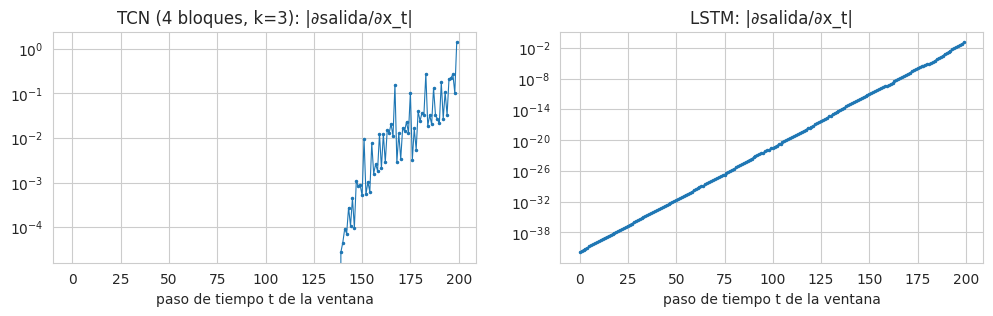

In [41]:
def pasos_que_influyen(modelo, L=200, repeticiones=5):
    modelo = modelo.cpu().eval()
    influencia = torch.zeros(L)
    for _ in range(repeticiones):
        x = torch.randn(1, L, num_features, requires_grad=True)
        modelo(x).sum().backward()
        influencia += x.grad.abs().sum(dim=-1).squeeze()
    return influencia

reset_seed()
inf_tcn = pasos_que_influyen(TCNModel(num_features, CANALES_TCN, 1, kernel_size=3, num_bloques=4))
inf_lstm = pasos_que_influyen(ModeloRecurrente('lstm', num_features, HIDDEN, 1, 1))

print("Pasos que influyen en la salida -> TCN (4 bloques):", int((inf_tcn > 0).sum()),
      "| LSTM:", int((inf_lstm > 0).sum()))

fig, axs = plt.subplots(1, 2, figsize=(12, 3))
for ax, inf, nombre in zip(axs, [inf_tcn, inf_lstm], ['TCN (4 bloques, k=3)', 'LSTM']):
    ax.semilogy(range(len(inf)), inf.numpy(), '.-', ms=3, lw=0.8)
    ax.set_title(f'{nombre}: |∂salida/∂x_t|')
    ax.set_xlabel('paso de tiempo t de la ventana')
plt.show()

La TCN usa **exactamente** los últimos $R=61$ pasos, de forma controlada por diseño. La LSTM, en teoría, usa toda la ventana, pero observe en escala logarítmica cómo la influencia (el gradiente) **decae exponencialmente a medida que nos alejamos del final** (aquí con pesos aleatorios, sin entrenar; el entrenamiento puede atenuar este efecto, pero no eliminarlo): es el problema de desvanecimiento de gradientes que, en la práctica, limita la memoria efectiva de las RNN.

## 6.6 Entrenamiento de la TCN

Entrenamos la TCN sobre **exactamente el mismo problema**: misma ventana (120 pasos, uno por hora durante 5 días), mismo horizonte (12 horas), mismos datos, mismo optimizador, mismo tamaño de batch y mismo número de épocas.

--- TCN ---
época 0: loss 0.13717, val loss 0.10078 -- tiempo de entrenamiento: 11.19 s
época 1: loss 0.10083, val loss 0.09771 -- tiempo de entrenamiento: 10.74 s
época 2: loss 0.09501, val loss 0.09724 -- tiempo de entrenamiento: 10.71 s
época 3: loss 0.09187, val loss 0.09657 -- tiempo de entrenamiento: 10.76 s
época 4: loss 0.08894, val loss 0.09678 -- tiempo de entrenamiento: 10.77 s
==> TCN: MAE 2.089 °C | 10.75 s/época | 7457 parámetros


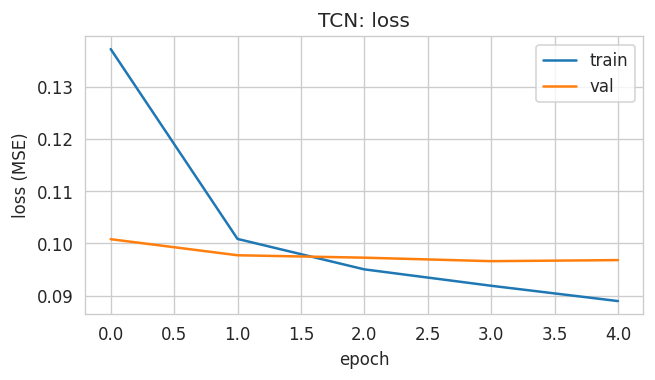

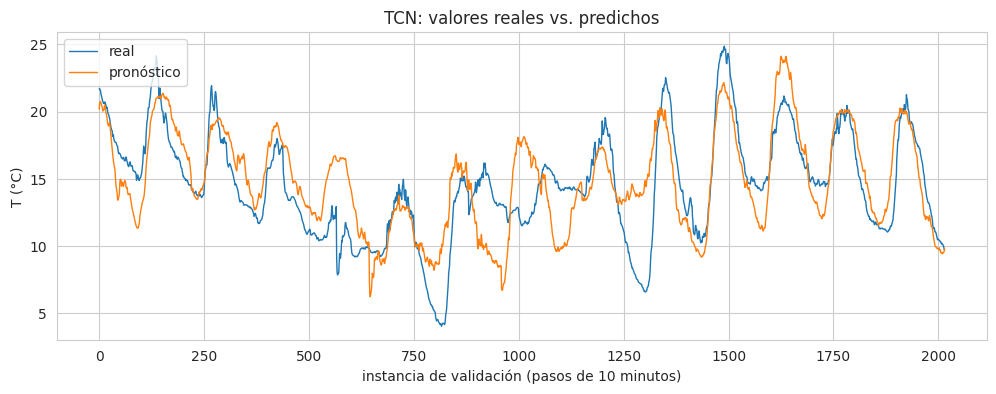

NameError: name 'modelos' is not defined

In [61]:
print("--- TCN ---")
modelo_tcn, historial_tcn, resultado_tcn = experimento(
    'TCN',
    lambda: TCNModel(num_features, CANALES_TCN, num_outputs, kernel_size=KERNEL_TCN,
                     longitud_ventana=VENTANA_HISTORICA).to(DEVICE),
    mostrar_graficos=True)
modelos['TCN'] = modelo_tcn
resultados.append(resultado_tcn)

--- TCN ---
época 0: loss 0.13717, val loss 0.10078 -- tiempo de entrenamiento: 11.53 s
época 1: loss 0.10083, val loss 0.09771 -- tiempo de entrenamiento: 11.28 s
época 2: loss 0.09501, val loss 0.09724 -- tiempo de entrenamiento: 11.33 s
época 3: loss 0.09187, val loss 0.09657 -- tiempo de entrenamiento: 11.27 s
época 4: loss 0.08894, val loss 0.09678 -- tiempo de entrenamiento: 13.66 s
==> TCN: MAE 2.089 °C | 11.89 s/época | 7457 parámetros


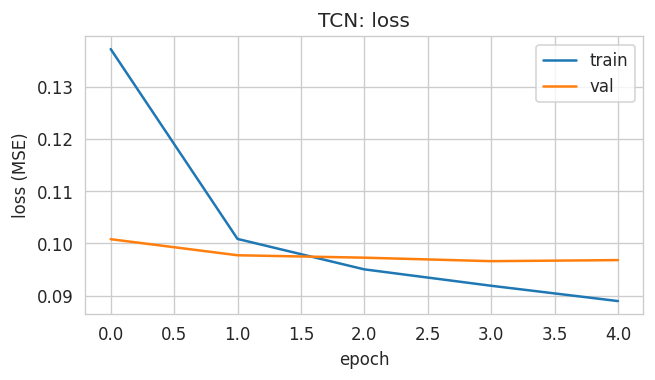

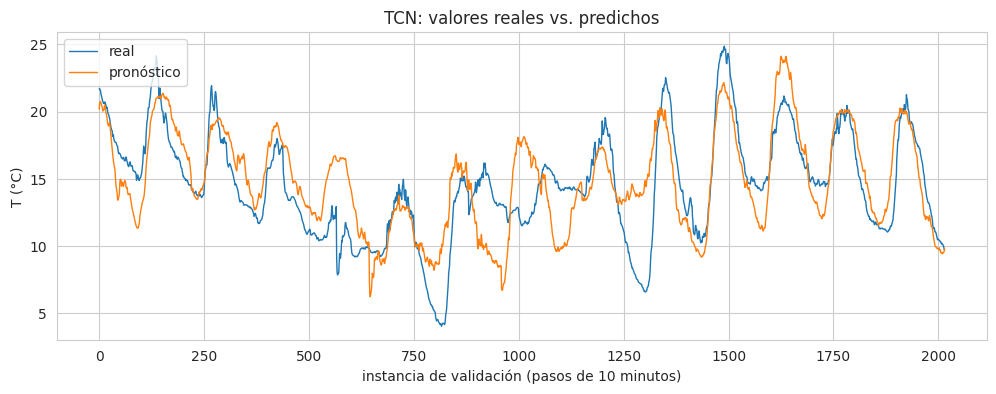

In [42]:
print("--- TCN ---")
modelo_tcn, historial_tcn, resultado_tcn = experimento(
    'TCN',
    lambda: TCNModel(num_features, CANALES_TCN, num_outputs, kernel_size=KERNEL_TCN,
                     longitud_ventana=VENTANA_HISTORICA).to(DEVICE),
    mostrar_graficos=True)
modelos['TCN'] = modelo_tcn
resultados.append(resultado_tcn)

# 7. Comparación: desempeño y costo computacional

## 7.1 Mismo problema, mismos datos

In [43]:
tabla_resultados = pd.DataFrame(resultados).set_index('modelo')
tabla_resultados.style.format({'val loss (MSE)': '{:.4f}', 'MAE (°C)': '{:.3f}', 'RMSE (°C)': '{:.3f}',
                               's/época (entren.)': '{:.2f}', 's inferencia (val)': '{:.2f}'})

,parámetros,val loss (MSE),MAE (°C),RMSE (°C),s/época (entren.),s inferencia (val)
modelo,,,,,,
RNN,1081,0.1097,2.231,2.861,2.93,0.33
LSTM,4231,0.1043,2.203,2.789,3.45,0.35
GRU,3181,0.0997,2.132,2.727,3.05,0.34
TCN,7457,0.0968,2.089,2.687,11.89,1.48


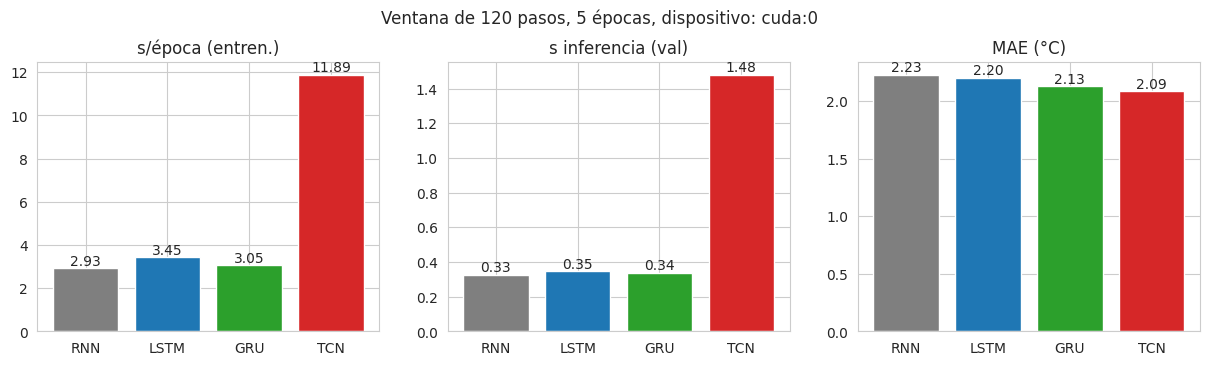

In [44]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
colores = ['tab:gray', 'tab:blue', 'tab:green', 'tab:red']
for ax, col in zip(axs, ['s/época (entren.)', 's inferencia (val)', 'MAE (°C)']):
    ax.bar(tabla_resultados.index, tabla_resultados[col], color=colores)
    ax.set_title(col)
    for i, v in enumerate(tabla_resultados[col]):
        ax.text(i, v, f'{v:.2f}', ha='center', va='bottom')
plt.suptitle(f'Ventana de {VENTANA_HISTORICA} pasos, {EPOCAS} épocas, dispositivo: {DEVICE}', y=1.03)
plt.show()

## 7.2 ¿Cómo escala el tiempo con la longitud de la ventana histórica?

La ventaja computacional de la TCN se hace evidente al aumentar la longitud $L$ de la secuencia. Medimos el tiempo de **un paso de entrenamiento** (forward + backward + actualización de pesos) y de **un paso de inferencia** sobre un batch de 256 secuencias, para distintas longitudes. Para cada $L$, la TCN usa el número de bloques necesario para cubrir toda la ventana.

| | RNN / LSTM / GRU | TCN |
|---|---|---|
| Operaciones **secuenciales** (no paralelizables) | $L$ (un paso tras otro) | $2 \cdot n_{bloques} = O(\log L)$ capas |
| Cómputo dentro de cada paso | pequeño (un vector de estado) | grande (todas las posiciones a la vez) |

Usamos datos aleatorios porque aquí solo nos interesa el costo computacional, no la calidad del pronóstico.

In [45]:
def medir_tiempos(modelo, L, device=DEVICE, batch_size=BATCH_SIZE, repeticiones=10):
    """Milisegundos promedio por paso de entrenamiento y por paso de inferencia."""
    modelo = modelo.to(device)
    x = torch.randn(batch_size, L, num_features, device=device)
    y = torch.randn(batch_size, 1, device=device)
    optimizer = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()

    def paso_entrenamiento():
        optimizer.zero_grad()
        loss_fn(modelo(x), y).backward()
        optimizer.step()

    modelo.train()
    for _ in range(3):                           # calentamiento
        paso_entrenamiento()
    sincronizar(device)
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        paso_entrenamiento()
    sincronizar(device)
    ms_entrenamiento = (time.perf_counter() - t0) / repeticiones * 1000

    modelo.eval()
    with torch.no_grad():
        for _ in range(3):
            modelo(x)
        sincronizar(device)
        t0 = time.perf_counter()
        for _ in range(repeticiones):
            modelo(x)
        sincronizar(device)
    ms_inferencia = (time.perf_counter() - t0) / repeticiones * 1000
    return ms_entrenamiento, ms_inferencia


def escalamiento(longitudes, device=DEVICE, repeticiones=10):
    filas = []
    for L in longitudes:
        candidatos = {
            'LSTM': lambda: ModeloRecurrente('lstm', num_features, HIDDEN, 1, 1),
            'GRU': lambda: ModeloRecurrente('gru', num_features, HIDDEN, 1, 1),
            'TCN': lambda: TCNModel(num_features, CANALES_TCN, 1, kernel_size=KERNEL_TCN, longitud_ventana=L),
        }
        for nombre, crear in candidatos.items():
            reset_seed()
            modelo = crear()
            ms_train, ms_inf = medir_tiempos(modelo, L, device, repeticiones=repeticiones)
            pasos_seq = L if nombre != 'TCN' else 2 * len(modelo.tcn)
            filas.append({'L': L, 'modelo': nombre, 'ms entrenamiento': ms_train,
                          'ms inferencia': ms_inf, 'pasos secuenciales': pasos_seq})
        print(f"L={L} listo")
    return pd.DataFrame(filas)


def graficar_escalamiento(df_tiempos, titulo):
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    for nombre, color in zip(['LSTM', 'GRU', 'TCN'], ['tab:blue', 'tab:green', 'tab:red']):
        d = df_tiempos[df_tiempos.modelo == nombre]
        axs[0].plot(d.L, d['ms entrenamiento'], 'o-', color=color, label=nombre)
        axs[1].plot(d.L, d['ms inferencia'], 'o-', color=color, label=nombre)
        axs[2].plot(d.L, d['pasos secuenciales'], 'o-', color=color, label=nombre)
    axs[0].set_title('ms por paso de entrenamiento (batch de 256)')
    axs[1].set_title('ms por paso de inferencia (batch de 256)')
    axs[2].set_title('operaciones secuenciales (profundidad)')
    for ax in axs:
        ax.set_xlabel('longitud de la ventana L')
        ax.legend()
    plt.suptitle(titulo, y=1.03)
    plt.show()

L=30 listo
L=60 listo
L=120 listo
L=240 listo
L=480 listo
L=720 listo


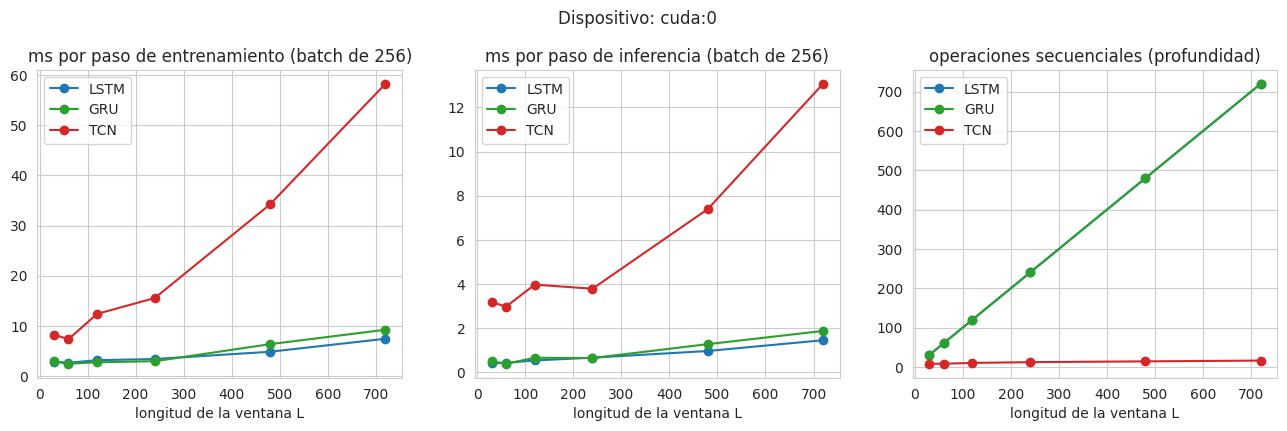

In [46]:
LONGITUDES = [30, 60, 120, 240, 480, 720]
tiempos_device = escalamiento(LONGITUDES, device=DEVICE)
graficar_escalamiento(tiempos_device, f'Dispositivo: {DEVICE}')

In [47]:
tiempos_device.pivot(index='L', columns='modelo', values='ms entrenamiento').assign(
    **{'LSTM / TCN': lambda d: d.LSTM / d.TCN}).round(2)

modelo,GRU,LSTM,TCN,LSTM / TCN
L,,,,
30,2.94,2.90,8.28,0.35
60,2.46,2.65,7.34,0.36
120,2.75,3.17,12.39,0.26
240,2.96,3.40,15.56,0.22
480,6.37,4.85,34.23,0.14
720,9.23,7.44,58.26,0.13


**¿Qué esperar?**

- **En GPU**, el tiempo de la LSTM/GRU crece aproximadamente **lineal** con $L$, porque cada paso de tiempo debe esperar al anterior. El de la TCN crece mucho más lento: todas las posiciones de la secuencia se procesan **en paralelo** y la cantidad de capas solo crece con $\log L$. Mientras más larga la ventana, mayor la ventaja de la TCN.
- **En CPU** (pocos núcleos), no hay paralelismo masivo que aprovechar y lo que importa es el **número total de operaciones**. Una TCN suele hacer **más** operaciones que una LSTM pequeña (calcula salidas en todas las posiciones de todas las capas), así que en CPU puede ser igual o incluso más lenta.

Es decir: **la ventaja de velocidad de la TCN no es "magia", es paralelismo**. Si hay GPU, corramos el mismo experimento en CPU para verlo directamente (con menos longitudes, porque en CPU es lento):

L=30 listo
L=60 listo
L=120 listo
L=240 listo


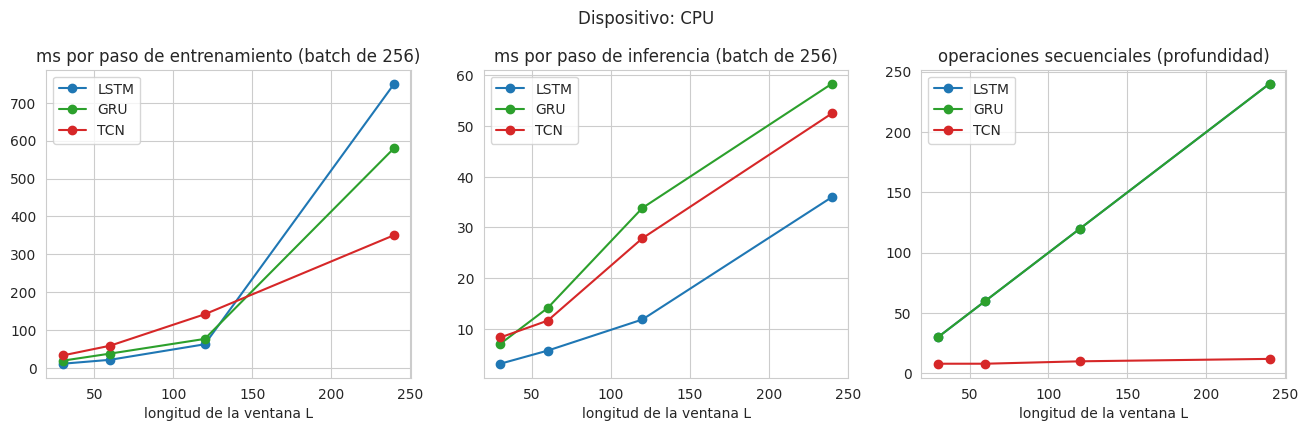

modelo,GRU,LSTM,TCN,LSTM / TCN
L,,,,
30,19.14,11.11,32.96,0.34
60,37.80,21.46,58.64,0.37
120,76.62,62.45,141.71,0.44
240,580.60,750.32,350.66,2.14


In [48]:
if DEVICE.type == 'cuda':
    tiempos_cpu = escalamiento([30, 60, 120, 240], device='cpu', repeticiones=3)
    graficar_escalamiento(tiempos_cpu, 'Dispositivo: CPU')
    display(tiempos_cpu.pivot(index='L', columns='modelo', values='ms entrenamiento')
            .assign(**{'LSTM / TCN': lambda d: d.LSTM / d.TCN}).round(2))
else:
    print("No hay GPU disponible: active una GPU en Colab para comparar ambos dispositivos.")

## 7.3 (Opcional) Usar la historia completa: 720 pasos con `step=1`

Hasta ahora submuestreamos la ventana (un valor por hora, `step=6`) para que las RNN fueran manejables. Con una TCN podemos usar **toda la resolución** (720 pasos de 10 minutos) con un costo moderado: solo se necesitan 8 bloques ($R=1021$). Este experimento entrena una época de cada modelo con la ventana completa. Cambie la variable a `True` para ejecutarlo (en GPU toma unos minutos; la LSTM es la parte lenta).

In [49]:
EJECUTAR_HISTORIA_COMPLETA = False

if EJECUTAR_HISTORIA_COMPLETA:
    train_full = SerieTiempoMultivariadaDataset(dataset, dataset[:, IDX_TARGET], 0, TRAIN_SPLIT,
                                                PAST_HISTORY, FUTURE_TARGET, 1, single_step=True, device=DEVICE)
    val_full = SerieTiempoMultivariadaDataset(dataset, dataset[:, IDX_TARGET], TRAIN_SPLIT, None,
                                              PAST_HISTORY, FUTURE_TARGET, 1, single_step=True, device=DEVICE)
    resultados_full = []
    for nombre, crear in {
        'LSTM (L=720)': lambda: ModeloRecurrente('lstm', num_features, HIDDEN, 1, 1),
        'TCN (L=720)': lambda: TCNModel(num_features, CANALES_TCN, 1, kernel_size=KERNEL_TCN,
                                        longitud_ventana=PAST_HISTORY),
    }.items():
        print(f"--- {nombre} ---")
        resultados_full.append(experimento(nombre, crear, train_full, val_full, epocas=1)[2])
    display(pd.DataFrame(resultados_full).set_index('modelo'))

# 8. Comparación con un modelo ingenuo (baseline de persistencia)

Para validar que los modelos tengan sentido, los comparamos con un modelo ingenuo que pronostica que la temperatura dentro de 12 horas será igual a la **última temperatura de la ventana que reciben los modelos** (es decir, con la misma información disponible).

Reportamos el MAE y el RMSE en **grados Celsius** y el $R^2$. No usamos el MAPE: sobre datos normalizados (centrados en cero) o sobre temperaturas en °C que cruzan el cero, el error porcentual se dispara al dividir por valores cercanos a cero y no es interpretable.

In [50]:
reals_c = a_grados(val_data.labels.squeeze(-1).cpu().numpy())
# última observación de temperatura de cada ventana: data tiene ejes (N, features, L)
persistencia_c = a_grados(val_data.data[:, IDX_TARGET, -1].cpu().numpy())

filas = [{'modelo': 'Persistencia (baseline)',
          'MAE (°C)': mean_absolute_error(reals_c, persistencia_c),
          'RMSE (°C)': math.sqrt(mean_squared_error(reals_c, persistencia_c)),
          'R2': r2_score(reals_c, persistencia_c)}]
for nombre, modelo in modelos.items():
    preds_c = a_grados(pronostico(modelo, val_data))
    filas.append({'modelo': nombre,
                  'MAE (°C)': mean_absolute_error(reals_c, preds_c),
                  'RMSE (°C)': math.sqrt(mean_squared_error(reals_c, preds_c)),
                  'R2': r2_score(reals_c, preds_c)})
pd.DataFrame(filas).set_index('modelo').round(3)

,MAE (°C),RMSE (°C),R2
modelo,,,
Persistencia (baseline),4.381,5.648,0.482
RNN,2.231,2.861,0.867
LSTM,2.203,2.789,0.874
GRU,2.132,2.727,0.879
TCN,2.089,2.687,0.883


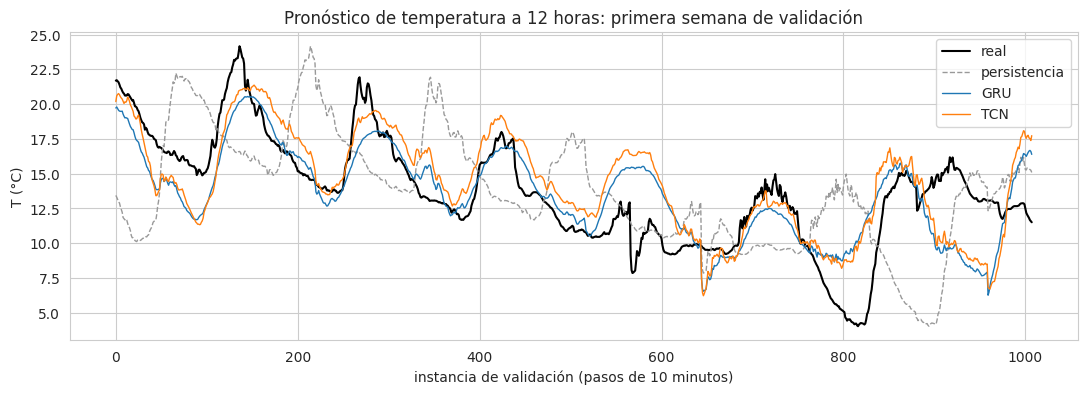

In [51]:
n = 144 * 7   # una semana de validación
plt.figure(figsize=(13, 4))
plt.plot(reals_c[:n], label='real', color='black', lw=1.5)
plt.plot(persistencia_c[:n], label='persistencia', color='0.6', lw=1, ls='--')
plt.plot(a_grados(pronostico(modelos['GRU'], val_data))[:n], label='GRU', lw=1)
plt.plot(a_grados(pronostico(modelos['TCN'], val_data))[:n], label='TCN', lw=1)
plt.ylabel('T (°C)')
plt.xlabel('instancia de validación (pasos de 10 minutos)')
plt.title('Pronóstico de temperatura a 12 horas: primera semana de validación')
plt.legend()
plt.show()

# 9. Conclusiones: ¿cuándo preferir una TCN?

**Ventajas de la TCN**
- **Paralelismo**: todas las posiciones de la secuencia se calculan simultáneamente. En GPU, el entrenamiento y la inferencia por lotes son más rápidos, y la ventaja crece con la longitud de la ventana (sección 7.2).
- **Profundidad logarítmica**: cubrir una ventana de $L$ pasos requiere $O(\log L)$ capas, no $L$ pasos secuenciales. Esto permite usar ventanas largas a resolución completa (sección 7.3).
- **Campo receptivo explícito y controlable**: sabemos exactamente cuántos pasos del pasado usa el modelo y lo elegimos con el kernel y el número de bloques (sección 6.3).
- **Gradientes más estables**: el camino del gradiente entre la salida y una entrada lejana tiene longitud $O(\log L)$ (y además hay conexiones residuales), en lugar de $L$ pasos de retropropagación a través del tiempo (sección 6.5).

**Desventajas y cuidados**
- **Memoria en inferencia**: para pronosticar, la TCN necesita la ventana completa de $R$ pasos; una RNN solo necesita su estado oculto y la nueva observación. En escenarios de *streaming*, paso a paso, una RNN puede ser más barata.
- **Campo receptivo fijo**: la TCN no puede usar información más allá de $R$ pasos; si el problema necesita más contexto, hay que rediseñar la red.
- **En CPU no siempre es más rápida**: la ventaja depende del hardware disponible para paralelizar.
- **La causalidad debe garantizarse**: un *padding* centrado (`padding='same'`) filtra información del futuro (sección 6.2).

**Ejercicios propuestos**
1. Varíe `CANALES_TCN` y `KERNEL_TCN` y observe el compromiso entre número de parámetros, error y tiempo (ver el Apéndice).
2. Entrene una TCN con un campo receptivo **menor** que la ventana (por ejemplo, `num_bloques=3`, $R=29$). ¿Cuánto empeora el error? ¿Qué nos dice esto sobre cuánta historia es realmente útil para pronosticar a 12 horas?
3. Active `EJECUTAR_HISTORIA_COMPLETA` y compare el error y el tiempo por época de la LSTM y la TCN con la ventana a resolución completa.
4. Modifique el problema para pronosticar las próximas 12 horas completas (`single_step=False`, `output_dim=72`) y compare los modelos.

# Apéndice: barridos de hiperparámetros (opcional)

Búsqueda de la mejor configuración en cuanto al número de neuronas de una única capa recurrente (RNN, LSTM y GRU) y al número de canales de la TCN. Cambie la variable a `True` para ejecutarlo (toma varios minutos).

In [52]:
EJECUTAR_BARRIDOS = False

if EJECUTAR_BARRIDOS:
    barrido = []
    for tipo in ['rnn', 'lstm', 'gru']:
        for neuronas in range(10, 61, 10):
            barrido.append(experimento(f'{tipo.upper()}-{neuronas}',
                                       lambda: ModeloRecurrente(tipo, num_features, neuronas, 1, 1),
                                       verbose=False)[2])
    for canales in [8, 16, 32, 64]:
        barrido.append(experimento(f'TCN-{canales}',
                                   lambda: TCNModel(num_features, canales, 1, kernel_size=KERNEL_TCN,
                                                    longitud_ventana=VENTANA_HISTORICA),
                                   verbose=False)[2])
    display(pd.DataFrame(barrido).set_index('modelo').round(3))